# Move alert — calibrating "significant"

**Question.** When should the desk be told that a token is moving? Too loose and the chat learns
to ignore it; too tight and the message arrives after the move.

**Definition tested.** For each token and each 5m bar:

1. **Residual return** $e_t = r_t - \beta_t\, r^{BTC}_t$ — the part of the move BTC does not
   explain. A market-wide move is one line about the market, not 25 token alerts.
   $\beta$ is an EWMA (half-life 7 days) of the token's sensitivity to BTC.
2. **Volatility** $\sigma_t$ — EWMA (half-life 3 days) of $e_t^2$. Both use only past bars, as the
   live alert would.
3. **Move score** over horizon $h$: $z_h = \sum_{h\ \text{bars}} e / (\sigma \sqrt{h})$, for
   $h$ = 5m, 15m, 1h.
4. **Alert** when any $|z_h| \ge k_h$; then the token is quiet for 2 hours (cool-down).

**Scoring.** A *big move* (the thing we want to hear about) is a residual move of at least
4σ over 4 hours. For a set of thresholds:

- **alerts/day** across the book — the noise budget;
- **recall** — share of big moves that got a same-direction alert before their peak;
- **precision** — share of alerts that belong to a big move;
- **move left** — median share of the big move still ahead when the alert fired (lateness).

Thresholds are chosen on the **first half** of the sample and read on the **second half**.

**Universe.** 25 of 37 MM3 tokens: those on a venue their strategy trades that we can fetch
(Binance, Bybit, MEXC). Binance history comes from monthly dumps (Jul–Sep); Bybit/MEXC run
mid-Jul to 12 Oct. Not covered: AI, BGB, BSV, BVIV, ELA, LAPTOP, QUID, TGBP, TRUF, UFD, XDP
(no fetchable venue or symbol) and AEDZ (a dirham stablecoin — a move alert means nothing on a peg).

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd()
while not (REPO_ROOT / "src").is_dir() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_formats = ["svg"]
plt.rcParams.update({"figure.figsize": (12, 4.2), "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.width", 160)

from src.data.query import get

VENUE = {
    "binance": "AIGENSYN DODO GAS HEMI MINA NEO PARTI QI SKL VTHO",
    "bybit": "AURORA AZTEC BILL HNT NYM",
    "mexc": "BTW CHECK CROSS DNX GENIUS MAGMA NOCK PUBLIC RHEA XCH",
}
TOKENS = {t: src for src, ts in VENUE.items() for t in ts.split()}
H = {"5m": 1, "15m": 3, "1h": 12}      # horizons, in 5m bars
VOL_HL, BETA_HL = 3 * 288, 7 * 288     # EWMA half-lives: 3 and 7 days
COOLDOWN = 24                          # 2h quiet per token after an alert
EVENT_BARS, EVENT_Z = 48, 4.0          # a big move: >= 4 sigma over 4h

btc = get("spot", "bybit", "btcusdt", "bars", "5m")["close"].astype(float)
r_btc = np.log(btc).diff()

frames = {}
for t, src in TOKENS.items():
    df = get("spot", src, f"{t.lower()}usdt", "bars", "5m")
    px = df["close"].astype(float)
    r = np.log(px).diff()
    rb = r_btc.reindex(r.index)
    cov = (r * rb).ewm(halflife=BETA_HL, min_periods=288).mean().shift(1)
    var_b = (rb ** 2).ewm(halflife=BETA_HL, min_periods=288).mean().shift(1)
    beta = (cov / var_b).clip(-3, 3)
    e = r - beta * rb
    sig = np.sqrt((e ** 2).ewm(halflife=VOL_HL, min_periods=288).mean().shift(1))
    f = pd.DataFrame({"px": px, "r": r, "e": e, "sig": sig, "beta": beta}).dropna()
    for k, h in H.items():
        f[f"z{k}"] = f["e"].rolling(h).sum() / (f["sig"] * np.sqrt(h))
    f["z4h"] = f["e"].rolling(EVENT_BARS).sum() / (f["sig"] * np.sqrt(EVENT_BARS))
    f["cum"] = f["e"].cumsum()
    frames[t] = f.dropna()

start = min(f.index[0] for f in frames.values())
end = max(f.index[-1] for f in frames.values())
SPLIT = start + (end - start) / 2
print(f"{len(frames)} tokens · {start:%Y-%m-%d} → {end:%Y-%m-%d} · train/test split {SPLIT:%Y-%m-%d}")

25 tokens · 2026-07-16 → 2026-10-12 · train/test split 2026-08-29


## 1. The tokens are not alike — and their tails are fat

Daily volatility runs from ~3% to ~20%, so a fixed "% move" threshold is noise on one token
and silence on another. The last columns count bars past 4σ per day: under a normal
distribution that would be about **0.02 per day** per horizon; here it is **1–4 per day**.
Thresholds must therefore be set on the data, not read off a normal table. *flat %* is the
share of 5m bars with no price change — a mark of thin books (DNX, PARTI, SKL, VTHO).

In [2]:
rows = []
for t, f in frames.items():
    days = len(f) / 288
    rows.append({"token": t, "venue": TOKENS[t], "days": round(days),
                 "daily σ %": f["sig"].median() * np.sqrt(288) * 100,
                 "β to BTC": f["beta"].median(), "flat %": (f["r"] == 0).mean() * 100,
                 **{f"|z{k}|≥4 /day": (f[f"z{k}"].abs() >= 4).sum() / days for k in H}})
vol_table = pd.DataFrame(rows).set_index("token").sort_values("daily σ %")
vol_table.round(2)

,venue,days,daily σ %,β to BTC,flat %,|z5m|≥4 /day,|z15m|≥4 /day,|z1h|≥4 /day
token,,,,,,,,
NEO,binance,77,3.06,0.87,22.07,1.64,1.44,1.30
RHEA,mexc,89,3.55,0.20,4.30,2.90,2.79,2.26
GAS,binance,77,3.61,0.76,35.77,1.86,1.74,1.54
VTHO,binance,77,3.74,0.56,48.54,1.47,1.43,1.67
AIGENSYN,binance,77,3.86,0.90,13.53,1.38,1.22,1.18
AZTEC,bybit,89,3.99,1.22,22.20,2.16,2.22,2.53
SKL,binance,77,4.43,0.75,49.27,1.28,1.43,1.31
GENIUS,mexc,89,4.96,0.49,0.77,1.58,1.43,1.65
BILL,bybit,89,5.63,1.00,11.98,1.69,1.31,0.80


## 2. Scoring machinery

In [3]:
def episodes(mask, gap):
    out, last = [], -10**9
    for i in np.flatnonzero(mask):
        if i - last >= gap:
            out.append(i)
            last = i
    return out


def events(f):
    # Big moves: (start, peak, sign). Start = 4h before the peak.
    z = f["z4h"].to_numpy()
    out = []
    for i in episodes(np.abs(z) >= EVENT_Z, EVENT_BARS):
        sign = int(np.sign(z[i]))
        seg = z[i:min(i + EVENT_BARS, len(z))] * sign
        peak = i + int(np.argmax(seg))
        out.append((max(peak - EVENT_BARS, 0), peak, sign))
    return out


def alerts(f, k, cols=None):
    cols = cols or {h: f"z{h}" for h in k}
    zs = {h: f[c].to_numpy() for h, c in cols.items()}
    ratio = np.max([np.abs(zs[h]) / k[h] for h in k], axis=0)
    out = []
    for i in episodes(ratio >= 1, COOLDOWN):
        best = max(k, key=lambda h: abs(zs[h][i]) / k[h])
        out.append((i, int(np.sign(zs[best][i]))))
    return out


def score(k_of, half, cols=None):
    n_al = n_hit = n_ev = n_caught = 0
    lefts, days = [], 0.0
    for t, f in frames.items():
        f = f[f.index < SPLIT] if half == "train" else f[f.index >= SPLIT]
        days += len(f) / 288
        al, ev, cum = alerts(f, k_of(t), cols), events(f), f["cum"].to_numpy()
        n_al += len(al)
        n_ev += len(ev)
        n_hit += sum(any(a <= i <= p and s == es for a, p, es in ev) for i, s in al)
        for a, p, es in ev:
            hits = [i for i, s in al if a <= i <= p and s == es]
            if hits:
                n_caught += 1
                move = cum[p] - cum[a]
                lefts.append(1 - (cum[hits[0]] - cum[a]) / move if move else 0.0)
    per_day = len(frames) / days
    return {"alerts/day": n_al * per_day, "precision": n_hit / max(n_al, 1),
            "recall": n_caught / max(n_ev, 1), "move left": np.median(lefts) if lefts else np.nan,
            "big moves/day": n_ev * per_day}

## 3. Baseline: a fixed % move

What most desks start with: alert when a token moves X% in an hour (raw price, no BTC
adjustment). X is set on the training half to the same budgets. This is the bar the
σ-based rule has to beat.

In [4]:
for f in frames.values():
    f["pct1h"] = f["r"].rolling(12).sum()

pct_rows = []
for x in [0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10, 0.12, 0.15]:
    s = score(lambda t, x=x: {"1h": x}, "train", cols={"1h": "pct1h"})
    pct_rows.append({"X": f"{x:.0%}", **s})
pct = pd.DataFrame(pct_rows).set_index("X")
pct.round(3)

,alerts/day,precision,recall,move left,big moves/day
X,,,,,
2%,79.002,0.039,0.981,0.657,2.409
3%,45.839,0.062,0.944,0.640,2.409
4%,29.854,0.090,0.916,0.561,2.409
5%,21.186,0.118,0.869,0.520,2.409
6%,15.557,0.152,0.850,0.449,2.409
8%,9.343,0.212,0.748,0.309,2.409
10%,5.854,0.273,0.598,0.257,2.409
12%,3.872,0.314,0.477,0.276,2.409
15%,2.229,0.434,0.393,0.122,2.409


## 4. σ thresholds: the budget frontier (training half)

Every combination of $k_{5m}, k_{15m}, k_{1h}$ on a grid (∞ = horizon off). For each budget, the
combination with the best recall (ties: most move left).

In [5]:
GRID = [5, 6, 7, 8, 10, 12, 15, np.inf]
rows = []
for k5, k15, k60 in itertools.product(GRID, GRID, GRID):
    if np.isinf([k5, k15, k60]).all():
        continue
    k = {"5m": k5, "15m": k15, "1h": k60}
    rows.append({"k5m": k5, "k15m": k15, "k1h": k60, **score(lambda t, k=k: k, "train")})
grid = pd.DataFrame(rows)

best = {}
for b in (3, 6, 10):
    c = grid[grid["alerts/day"] <= b].sort_values(["recall", "move left"], ascending=False)
    best[b] = c.iloc[0]
pd.DataFrame(best).T.rename_axis("budget").round(3)

,k5m,k15m,k1h,alerts/day,precision,recall,move left,big moves/day
budget,,,,,,,,
3,inf,10.0,6.0,2.972,0.561,0.720,0.210,2.409
6,12.0,7.0,5.0,5.719,0.378,0.841,0.431,2.409
10,8.0,6.0,5.0,8.735,0.260,0.869,0.540,2.409


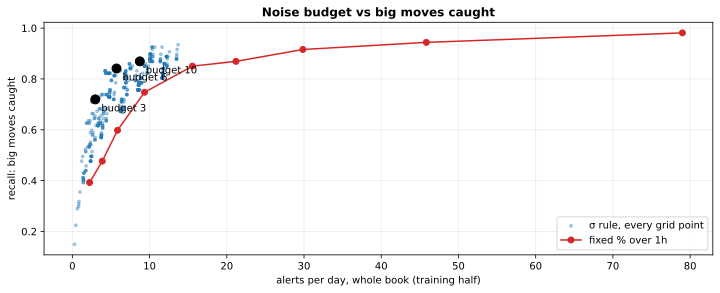

In [6]:
fig, ax = plt.subplots()
ok = grid[grid["alerts/day"] <= 15]
ax.scatter(ok["alerts/day"], ok["recall"], s=8, alpha=0.35, label="σ rule, every grid point")
ax.plot(pct["alerts/day"], pct["recall"], "o-", color="tab:red", label="fixed % over 1h")
for b, r in best.items():
    ax.scatter(r["alerts/day"], r["recall"], s=80, color="black", zorder=3)
    ax.annotate(f"budget {b}", (r["alerts/day"], r["recall"]), xytext=(6, -12),
                textcoords="offset points")
ax.set_xlabel("alerts per day, whole book (training half)")
ax.set_ylabel("recall: big moves caught")
ax.set_title("Noise budget vs big moves caught")
ax.legend(loc="lower right")
plt.show()

## 5. Out of sample (test half)

The thresholds picked above, unchanged, on the second half. If the budget and recall hold
here, the calibration is not just fitting its own sample.

In [7]:
oos = []
for b, r in best.items():
    k = {"5m": r["k5m"], "15m": r["k15m"], "1h": r["k1h"]}
    for half in ("train", "test"):
        oos.append({"budget": b, "half": half,
                    "rule": f"5m≥{k['5m']:g}σ · 15m≥{k['15m']:g}σ · 1h≥{k['1h']:g}σ",
                    **score(lambda t, k=k: k, half)})
for x in ("4%", "6%", "8%"):
    v = float(x.strip("%")) / 100
    oos.append({"budget": "-", "half": "test", "rule": f"fixed {x} over 1h",
                **score(lambda t, v=v: {"1h": v}, "test", cols={"1h": "pct1h"})})
pd.DataFrame(oos).set_index(["budget", "half"]).round(3)

rule  alerts/day  precision  recall  move left  big moves/day
budget half                                                                                     
3      train  5m≥infσ · 15m≥10σ · 1h≥6σ       2.972      0.561   0.720      0.210          2.409
       test   5m≥infσ · 15m≥10σ · 1h≥6σ       3.332      0.568   0.747      0.361          2.499
6      train    5m≥12σ · 15m≥7σ · 1h≥5σ       5.719      0.378   0.841      0.431          2.409
       test     5m≥12σ · 15m≥7σ · 1h≥5σ       5.881      0.391   0.869      0.499          2.499
10     train     5m≥8σ · 15m≥6σ · 1h≥5σ       8.735      0.260   0.869      0.540          2.409
       test      5m≥8σ · 15m≥6σ · 1h≥5σ       8.809      0.275   0.899      0.508          2.499
-      test            fixed 4% over 1h      44.072      0.070   0.929      0.661          2.499
       test            fixed 6% over 1h      25.595      0.112   0.859      0.661          2.499
       test            fixed 8% over 1h      16.281      0.155   0.798      0.604          2.499

## 6. Alternative: per-token rarity

Instead of one σ threshold for all tokens, give each token its own threshold: the level its
$|z|$ reached only once in N bars during the training half. This forces every token to alert
at the same rate — fair in count, but it also means a quiet token alerts on smaller news.

In [8]:
Q = [1/1000, 1/2000, 1/5000, 1/10000, None]
qcache = {t: {h: f[f.index < SPLIT][f"z{h}"].abs() for h in H} for t, f in frames.items()}


def rarity(q5, q15, q60):
    ks = {t: {h: (np.inf if q is None else float(qcache[t][h].quantile(1 - q)))
              for h, q in zip(H, (q5, q15, q60))} for t in frames}
    return lambda t: ks[t]


rows = []
for q in itertools.product(Q, Q, Q):
    if all(x is None for x in q):
        continue
    rows.append({"q": q, **score(rarity(*q), "train")})
rgrid = pd.DataFrame(rows)
rr = []
for b in (3, 6, 10):
    c = rgrid[rgrid["alerts/day"] <= b].sort_values(["recall", "move left"], ascending=False).iloc[0]
    rr.append({"budget": b, "1-in-N (5m,15m,1h)": tuple(None if x is None else round(1 / x) for x in c["q"]),
               **{f"test {k}": v for k, v in score(rarity(*c["q"]), "test").items()}})
pd.DataFrame(rr).set_index("budget").round(3)

,"1-in-N (5m,15m,1h)",test alerts/day,test precision,test recall,test move left,test big moves/day
budget,,,,,,
3,"(10000, 2000, 1000)",3.610,0.462,0.667,0.357,2.499
6,"(1000, 1000, 1000)",6.942,0.291,0.747,0.468,2.499
10,"(1000, 1000, 1000)",6.942,0.291,0.747,0.468,2.499


## 7. The budget-6 rule in detail (test half)

Which tokens raise the alerts, and how early it was on the largest moves.

In [9]:
r6 = best[6]
K6 = {"5m": r6["k5m"], "15m": r6["k15m"], "1h": r6["k1h"]}
per_tok, big = [], []
for t, f in frames.items():
    f = f[f.index >= SPLIT]
    al, ev, cum = alerts(f, K6), events(f), f["cum"].to_numpy()
    days = len(f) / 288
    per_tok.append({"token": t, "alerts/day": len(al) / days, "big moves/day": len(ev) / days})
    for a, p, s in ev:
        hits = [i for i, si in al if a <= i <= p and si == s]
        move = cum[p] - cum[a]
        big.append({"token": t, "peak": f.index[p], "dir": "up" if s > 0 else "down",
                    "move σ": abs(f["z4h"].iloc[p]), "raw move %": (f["px"].iloc[p] / f["px"].iloc[a] - 1) * 100,
                    "alerted": f.index[hits[0]] if hits else pd.NaT,
                    "min before peak": (p - hits[0]) * 5 if hits else np.nan,
                    "move left": (1 - (cum[hits[0]] - cum[a]) / move) if hits and move else np.nan})
per_tok = pd.DataFrame(per_tok).set_index("token").sort_values("alerts/day", ascending=False)
print("alerts per day by token (test half)")
print(per_tok.round(2).to_string())

alerts per day by token (test half)
          alerts/day  big moves/day
token                              
MAGMA           0.43           0.18
BTW             0.41           0.11
RHEA            0.41           0.20
PUBLIC          0.38           0.18
AZTEC           0.32           0.20
VTHO            0.31           0.12
QI              0.31           0.15
AURORA          0.29           0.18
DNX             0.29           0.09
CROSS           0.27           0.11
XCH             0.25           0.05
HNT             0.23           0.09
NYM             0.23           0.09
CHECK           0.23           0.07
AIGENSYN        0.22           0.12
SKL             0.19           0.03
BILL            0.18           0.05
MINA            0.12           0.06
GENIUS          0.11           0.05
NOCK            0.11           0.05
DODO            0.09           0.09
GAS             0.09           0.06
HEMI            0.09           0.06
NEO             0.06           0.03
PARTI           0.06        

In [10]:
big = pd.DataFrame(big).sort_values("move σ", ascending=False)
print("largest 15 big moves in the test half")
big.head(15).round(2)

largest 15 big moves in the test half


/tmp/ipykernel_882620/4081695358.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  big.head(15).round(2)


,token,peak,dir,move σ,raw move %,alerted,min before peak,move left
16,QI,2026-09-25 01:30:00,up,14.69,102.91,2026-09-25 00:45:00,45.0,0.91
68,GENIUS,2026-09-17 11:40:00,up,12.81,22.43,2026-09-17 11:30:00,10.0,0.91
50,NYM,2026-09-25 13:35:00,up,12.09,43.46,2026-09-25 11:30:00,125.0,0.77
33,AZTEC,2026-09-04 10:45:00,up,12.06,24.08,2026-09-04 09:40:00,65.0,0.72
81,PUBLIC,2026-09-28 14:10:00,up,11.57,139.08,2026-09-28 12:25:00,105.0,0.74
90,RHEA,2026-09-18 06:35:00,up,10.63,50.32,2026-09-18 05:50:00,45.0,0.78
19,SKL,2026-09-19 21:50:00,up,10.24,30.73,2026-09-19 19:55:00,115.0,0.78
21,VTHO,2026-09-10 01:50:00,up,10.19,69.04,2026-09-10 00:00:00,110.0,0.74
29,AURORA,2026-09-21 16:55:00,up,9.99,101.61,2026-09-21 13:30:00,205.0,0.89
48,NYM,2026-09-06 19:10:00,up,9.76,82.77,2026-09-06 15:25:00,225.0,0.76


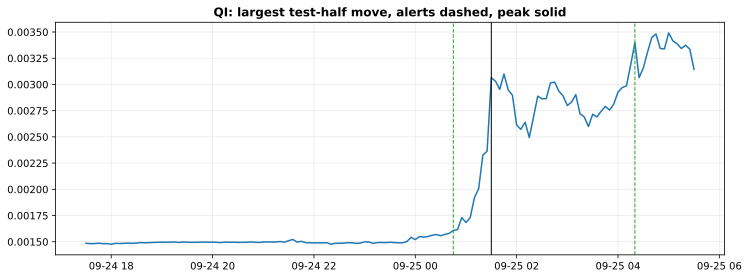

In [11]:
t0 = big.iloc[0]
f = frames[t0["token"]]
win = f.loc[t0["peak"] - pd.Timedelta(hours=8): t0["peak"] + pd.Timedelta(hours=4)]
fig, ax = plt.subplots()
ax.plot(win.index, win["px"], color="tab:blue")
for i, s in alerts(f, K6):
    ts = f.index[i]
    if win.index[0] <= ts <= win.index[-1]:
        ax.axvline(ts, color="tab:red" if s < 0 else "tab:green", ls="--", lw=1)
ax.axvline(t0["peak"], color="black", lw=1)
ax.set_title(f"{t0['token']}: largest test-half move, alerts dashed, peak solid")
plt.show()

## 8. The market line

Moves BTC explains are stripped from the token alerts above, so the market needs its own line.
The same score on BTC's own returns (σ from BTC's EWMA), at the budget-6 thresholds:

In [12]:
b = pd.DataFrame({"r": r_btc}).dropna()
b["sig"] = np.sqrt((b["r"] ** 2).ewm(halflife=VOL_HL, min_periods=288).mean().shift(1))
for k, h in H.items():
    b[f"z{k}"] = b["r"].rolling(h).sum() / (b["sig"] * np.sqrt(h))
b = b.dropna()
mk = alerts(b, K6)
print(f"BTC market alerts: {len(mk)} over {len(b) / 288:.0f} days = {len(mk) / (len(b) / 288):.2f} per day")

BTC market alerts: 24 over 90 days = 0.27 per day


## Reading the results

- **One σ rule beats a fixed %** at every budget: the frontier in §4 sits above the red line,
  because a fixed % spends its budget on the most volatile tokens.
- **The 15m and 1h horizons do the work.** The best combinations switch the 5m horizon off or
  set it high (8–12σ): a single 5m bar on these books is mostly a thin-book print, not news.
- **Per-token rarity (§6) does worse** than one shared σ threshold: forcing equal counts makes
  quiet tokens alert on small moves and volatile ones miss real ones.
- **Caveats.** The big-move definition uses the same σ as the alert, so recall is measured in
  the rule's own units; precision is the conservative number. 5m spot bars from one venue per
  token stand in for the consolidated CoinRoutes book the live alert would read. Intraday
  seasonality is ignored. Twelve MM3 tokens are not covered.